# Task 2 - Clustering

In [138]:
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
import numpy as np
from IPython.display import display

In [139]:
data = pd.read_pickle("clean_data.pkl")
data.head(3)

,url,name,price,brand,motor_power_w,battery_capacity_wh,range_km,speed_kmh,color
0,https://www.geekbuying.com/item/Ausom-L1-Elect...,"Ausom L1 Electric Scooter, 800W Motor, 48V 15....",10656.98,ausom,500.0,998.4,90.0,20.0,NaN
1,https://www.geekbuying.com/item/Kukirin-G2-Fol...,Kukirin G2 Foldable Electric Scooter 2026 Upgr...,11870.77,kukirin,800.0,NaN,55.0,45.0,NaN
2,https://www.geekbuying.com/item/BOYUEDA-Q7-Pro...,"BOYUEDA Q7 Pro Max Electric Scooter, 1600W*2 M...",18910.69,boyueda,3200.0,1456.0,100.0,70.0,NaN


# 1 Nerelevantní data

nejsou relevantní `url`, `name` - jsou jenom informativní pro lidí, ne pro statistický model

In [140]:
data = data.drop(columns=["url", "price"])

# 2 Chybějící hodnoty

- Z explorativní analýzy víme, že jsou tam data s 6 a více chybějícími hodnotami - ty odstraníme
- Další způsoby si poradit s chybějícími hodnotami:
1. Vyměnit na novou kategorii např. "nan"/"unknown"
2. Vyměnit na nečastější/matematicky očekávanou hodnotu (kategorii)


In [141]:
data["brand"] = data["brand"].cat.add_categories(["Unknown"]).fillna("Unknown")
data["color"] = data["color"].fillna(data["color"].mode()[0])

# 3 Odlehlé hodnoty

zbavíme se všech numerických hodnot iterativním odstraněním odléhlých hodnot s `1.5 * IQR`; tím nám zůstanou maximálně věrohodná data

Rows before removing: 334

motor_power_w          500.0
battery_capacity_wh    324.0
range_km                45.0
speed_kmh               15.0
dtype: float64

Rows after removing: 126


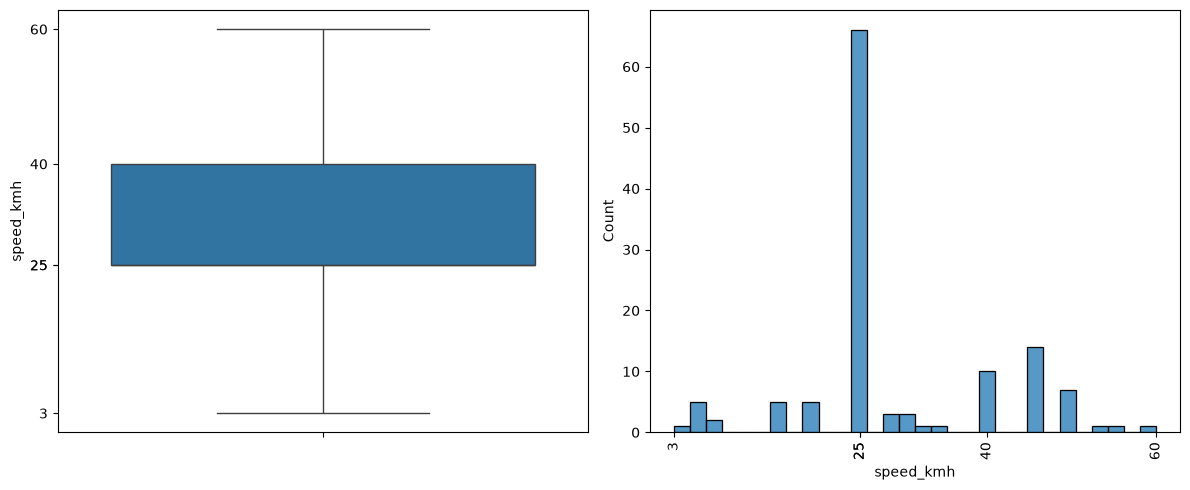

In [142]:
def plot_speed_distribution(data):
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    speed = data["speed_kmh"].dropna()

    sns.boxplot(y=speed, ax=axes[0])
    speed_ticks = speed.describe()[["min", "25%", "50%", "75%", "max"]].to_numpy()
    axes[0].set_yticks(speed_ticks)
    axes[0].set_yticklabels([f"{value:,.0f}" for value in speed_ticks])

    sns.histplot(x=speed, bins=30, ax=axes[1])
    axes[1].set_xticks(speed_ticks)
    axes[1].set_xticklabels([f"{value:,.0f}" for value in speed_ticks])
    axes[1].tick_params(axis="x", labelrotation=90)

    fig.tight_layout()
    plt.show()


numeric_columns = ["motor_power_w", "battery_capacity_wh", "range_km", "speed_kmh"]

def get_rid_of_price_outliers():
    global data

    while True:
        q1 = data[numeric_columns].quantile(0.25)
        q3 = data[numeric_columns].quantile(0.75)
        iqr = q3 - q1
        lower_bounds = q1 - 1.5 * iqr
        upper_bounds = q3 + 1.5 * iqr
        within_bounds = (
            data[numeric_columns].notna().all(axis=1)
            & data[numeric_columns].ge(lower_bounds).all(axis=1)
            & data[numeric_columns].le(upper_bounds).all(axis=1)
        )

        filtered_data = data.loc[within_bounds]
        if len(filtered_data) == len(data):
            break
        data = filtered_data

    print(iqr, end="\n\n")


print(f"Rows before removing: {len(data)}", end="\n\n")
get_rid_of_price_outliers()
print(f"Rows after removing: {len(data)}")
plot_speed_distribution(data)

# 4 Diskretizace numerických atributů

In [143]:
labels = {
    "motor_power_w"      : ["low", "medium", "high"],
    "battery_capacity_wh": ["small", "medium", "large"],
    "range_km"           : ["short", "medium", "long"],
    "speed_kmh"          : ["slow", "medium", "fast"]
}
for numeric_column in numeric_columns:
    data[numeric_column] = pd.cut(
        data[numeric_column],
        bins=[
            data[numeric_column].min(),
            data[numeric_column].mean(),
            data[numeric_column].max(),
            float("inf")
        ],
        labels=labels[numeric_column]
    ).astype("category")

<class 'pandas.DataFrame'>
Index: 126 entries, 0 to 328
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype   
---  ------               --------------  -----   
 0   name                 126 non-null    str     
 1   brand                126 non-null    category
 2   motor_power_w        125 non-null    category
 3   battery_capacity_wh  125 non-null    category
 4   range_km             125 non-null    category
 5   speed_kmh            125 non-null    category
 6   color                126 non-null    category
dtypes: category(6), str(1)
memory usage: 6.7 KB
None


,name,brand,motor_power_w,battery_capacity_wh,range_km,speed_kmh,color
0,"Ausom L1 Electric Scooter, 800W Motor, 48V 15....",ausom,low,medium,medium,slow,black
7,"GELEIPU Z1 Pro Electric Scooter, 1200W*2 Motor...",geleipu,medium,medium,medium,slow,black
8,KuKirin G2 Max Electric Scooter 10 Inch Off-ro...,kukirin,medium,medium,medium,slow,black
12,TWOFISH TF03 Electric Scooter with Removable S...,twofish,low,medium,short,slow,blue
18,RANDRIDE YG90A Electric Bike 1000W Motor 45km/...,randride,medium,medium,short,medium,black


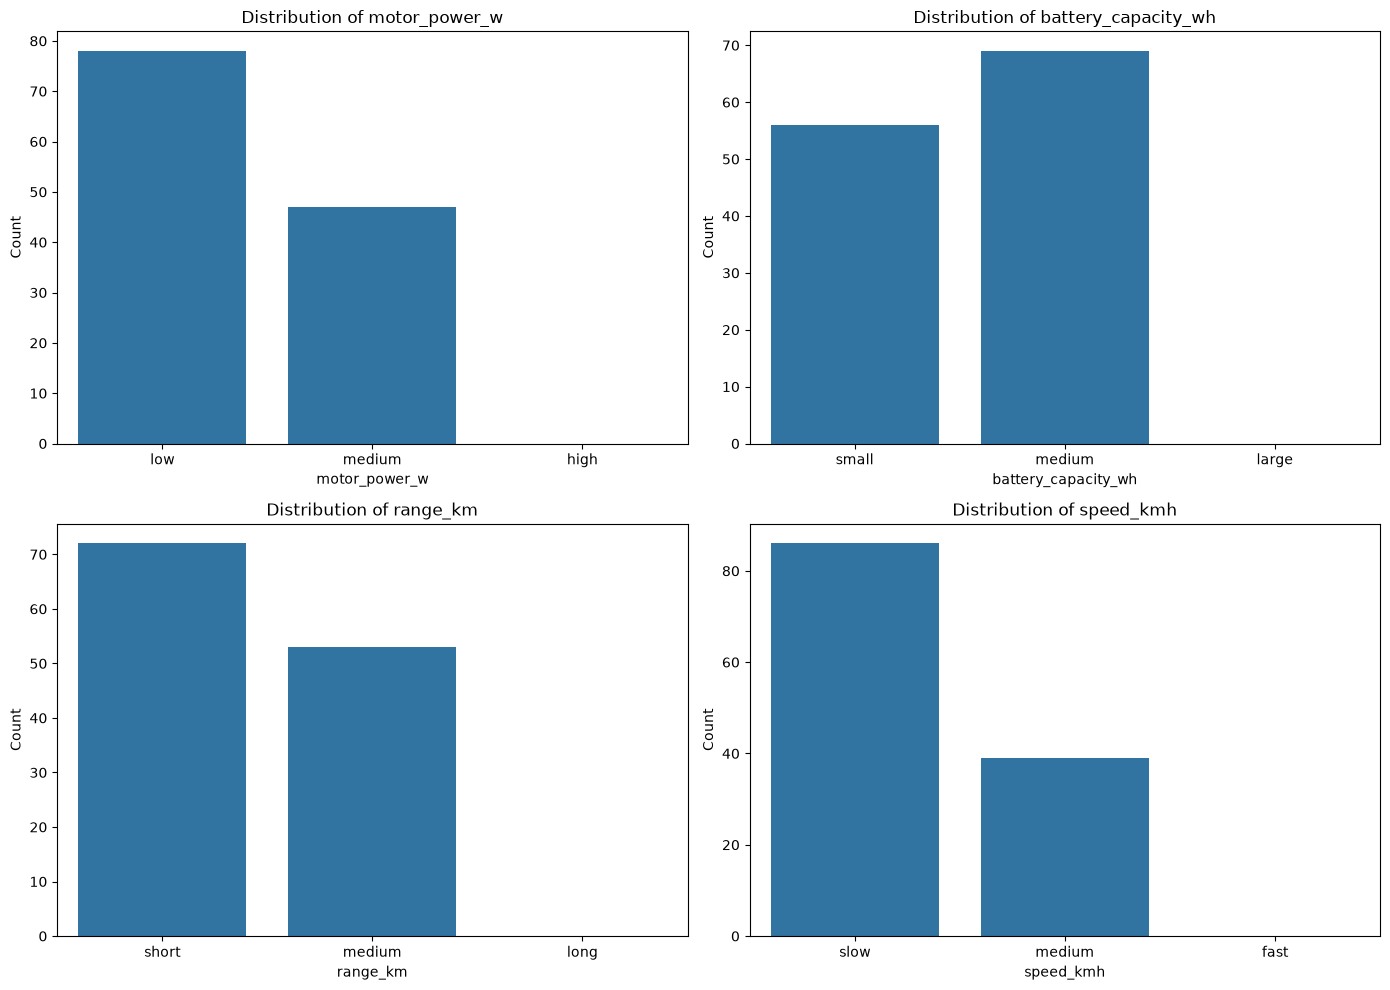

In [144]:
def draw_barplots(data):
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    for axis, numeric_column in zip(axes.flat, numeric_columns):
        counts = data[numeric_column].value_counts().reindex(labels[numeric_column], fill_value=0)
        sns.barplot(x=counts.index, y=counts.values, ax=axis)
        axis.set_title(f"Distribution of {numeric_column}")
        axis.set_ylabel("Count")

    fig.tight_layout()
    plt.show()


print(data.info())
display(data.head(5))
draw_barplots(data)

In [145]:
data.to_csv("cluster_data.csv", index=False)
print("Saved cluster_data.csv")

Saved cluster_data.csv
